In [1]:
import sys 
sys.path.insert(0 ,'../src')

from utils.gpu import setup_gpu

setup_gpu()

I0000 00:00:1793036167.074647   24969 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793036168.662241   24969 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [2]:
import tensorflow as tf 
import numpy as np 
import PIL

In [3]:
base_model = tf.keras.applications.InceptionV3(
    include_top = False,
    weights = 'imagenet',
    pooling = 'avg',
    input_shape = (299,299,3)
)
base_model.trainable = False


In [4]:
img_path = "../data/Train/Glioma/images/gg (103).jpg"
img = PIL.Image.open(img_path).convert("RGB").resize((299,299))
x = np.array(img,dtype='float32')
x = np.expand_dims(x , axis=0)
x = tf.keras.applications.inception_v3.preprocess_input(x)

features = base_model(x , training=False)
print(features.shape)
print(features.device)
print(features.numpy()[0][:10])

(1, 2048)
/job:localhost/replica:0/task:0/device:GPU:0
[0.3749102  0.16955723 0.47338453 0.66498655 0.10062481 0.14196044
 0.3676071  0.3583477  0.05887125 0.1281275 ]


In [5]:
from pathlib import Path

In [6]:
DATA_DIR = Path("../data")

def print_tree(folder: Path , indent: str) :
    for sub in (subFolder for subFolder in folder.iterdir() if subFolder.is_dir()):
        n_files = sum(1 for file in sub.iterdir() if file.is_file())
        infos = f'--> ({n_files}) files' if n_files else ""
        print(f"{indent}{sub.name}{infos}")
        print_tree(sub , indent + "    ")
        
        
print_tree(DATA_DIR , "     ")

     Train
         Glioma
             images--> (1153) files
             labels--> (1153) files
         Meningioma
             images--> (1449) files
             labels--> (1449) files
         No Tumor
             images--> (711) files
             labels--> (711) files
         Pituitary
             images--> (1424) files
             labels--> (1424) files
     Val
         Glioma
             images--> (136) files
             labels--> (136) files
         Meningioma
             images--> (140) files
             labels--> (140) files
         No Tumor
             images--> (100) files
             labels--> (100) files
         Pituitary
             images--> (136) files
             labels--> (136) files


In [7]:
import pandas as pd

DATA_DIR = Path("../data")
IMG_EXTS = {".jpg", ".jpeg", ".png"}

rows = []
for split_dir in sorted(p for p in DATA_DIR.iterdir() if p.is_dir()):
    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        images = {f.stem for f in (class_dir / "images").iterdir() if f.suffix.lower() in IMG_EXTS}
        labels = {f.stem for f in (class_dir / "labels").iterdir() if f.suffix == ".txt"}

        rows.append({
            "split": split_dir.name,
            "class": class_dir.name,
            "images": len(images),
            "labels": len(labels),
            "pairs": len(images & labels),
            "images_without_label": len(images - labels),
            "labels_without_image": len(labels - images),
        })

pairing = pd.DataFrame(rows)

class_counts = pairing.groupby("class")["images"].sum()
class_names = pairing['class'].unique()
pairing

,split,class,images,labels,pairs,images_without_label,labels_without_image
0,Train,Glioma,1153,1153,1153,0,0
1,Train,Meningioma,1449,1449,1449,0,0
2,Train,No Tumor,711,711,711,0,0
3,Train,Pituitary,1424,1424,1424,0,0
4,Val,Glioma,136,136,136,0,0
5,Val,Meningioma,140,140,140,0,0
6,Val,No Tumor,100,100,98,2,2
7,Val,Pituitary,136,136,136,0,0


Text(0.5, 1.0, 'Images par classe (Train)')

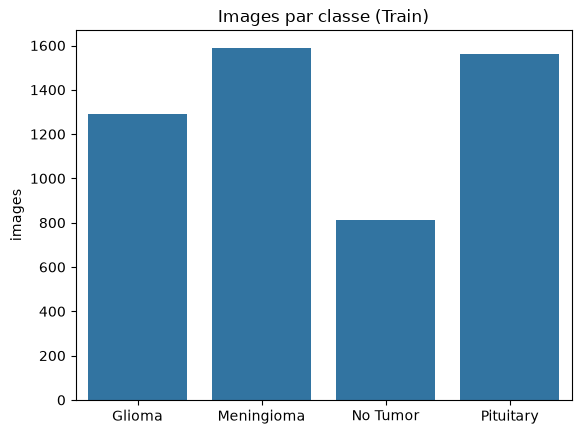

In [8]:
import seaborn as sns

sns.barplot(x=class_names , y=class_counts).set_title("Images par classe (Train)")

In [9]:
(pairing.groupby("class")["images"].sum() / pairing["images"].sum() * 100).round(1)


class
Glioma        24.6
Meningioma    30.3
No Tumor      15.5
Pituitary     29.7
Name: images, dtype: float64

In [10]:
from PIL import Image, UnidentifiedImageError

ALLOWED_EXTS = {".jpg", ".jpeg", ".png"}
valid, invalid = [], []

for file in DATA_DIR.rglob("*"):
    if not file.is_file() or file.parent.name != "images":
        continue                                   

    if file.suffix.lower() not in ALLOWED_EXTS:
        invalid.append((file, "extension"))
        continue

    try:
        with Image.open(file) as img:
            img.verify()                           
        with Image.open(file) as img:
            img.load()
        valid.append(file)
    except (UnidentifiedImageError, OSError) as e:
        invalid.append((file, f"corrompue: {e}"))

print(f"Valides : {len(valid)} | Invalides : {len(invalid)}")


Valides : 5249 | Invalides : 0


Text(0.5, 1.0, 'Images par classe')

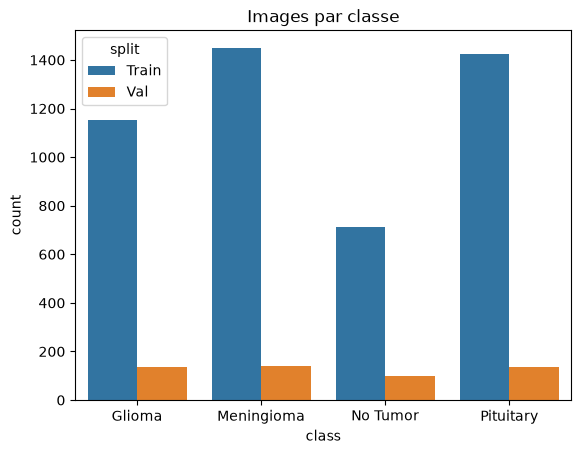

In [11]:
import pandas as pd

df = pd.DataFrame({
    "class": [f.parent.parent.name for f in valid],
    "split": [f.parents[2].name for f in valid],
    "path" : [f for f in valid]
})

sns.countplot(data=df, x="class", hue="split").set_title("Images par classe")


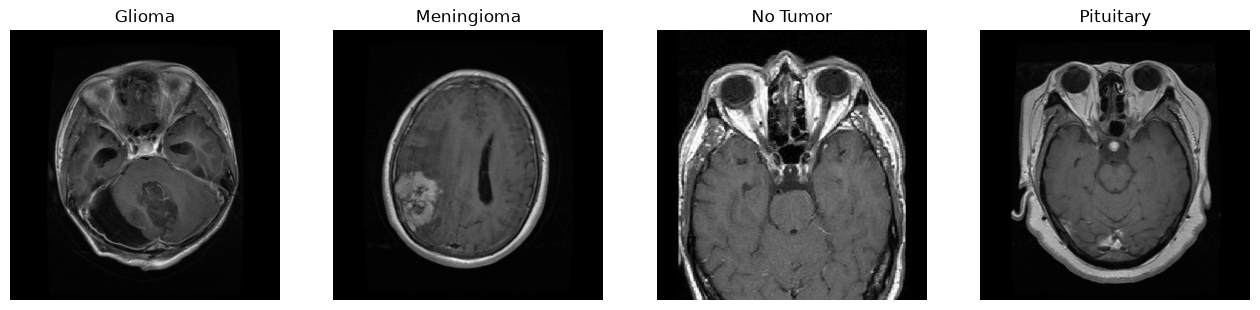

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax , cls in zip(axes , sorted(df['class'].unique())):
    sample = next(f for f in valid if f.parent.parent.name == cls)
    ax.imshow(Image.open(sample))
    ax.set_title(cls)
    ax.axis('off')
    
plt.show()
    
    

In [13]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["class"], random_state=42)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["class"], random_state=42)

In [14]:
import shutil

OUT_DIR = Path("../processed/classification")

for split_name, split_df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    for path, cls in zip(split_df["path"], split_df["class"]):
        dest = OUT_DIR / split_name / cls
        dest.mkdir(parents=True, exist_ok=True)
        shutil.copy2(path, dest / Path(path).name)


In [15]:
train_df["set"] = "train"
val_df["set"]   = "val"
test_df["set"]  = "test"

split_df = pd.concat([train_df, val_df, test_df])

pd.crosstab(split_df["class"], split_df["set"], margins=True)


set,test,train,val,All
class,,,,
Glioma,194,902,193,1289
Meningioma,239,1112,238,1589
No Tumor,121,568,122,811
Pituitary,234,1092,234,1560
All,788,3674,787,5249


In [16]:
OUT_DIR = Path("../processed")

split_df[["path", "class", "set"]].to_csv(OUT_DIR / 'split.csv', index=False)

In [17]:
import random
import numpy as np
from PIL import Image, ImageFilter, ImageOps

TRAIN_DIR = Path("../processed/classification/train")
TARGET = 1112
random.seed(42)
rng = np.random.default_rng(42)

def blur(img):
    return img.filter(ImageFilter.GaussianBlur(radius=random.uniform(1, 2)))

def noise(img):
    arr = np.array(img, dtype=np.float32)
    arr += rng.normal(0, 10, arr.shape)
    return Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))

def flip(img):
    return ImageOps.mirror(img)

AUGMENTATIONS = {"blur": blur, "noise": noise, "flip": flip}

for class_dir in sorted(TRAIN_DIR.iterdir()):
    
    originals = sorted(class_dir.glob("*.jpg"))
    missing = TARGET - len(originals)
    print(f"{class_dir.name}: {len(originals)} → +{max(missing, 0)}")

    for i in range(missing):
        src = random.choice(originals)
        name, aug = random.choice(list(AUGMENTATIONS.items()))
        with Image.open(src) as img:
            new_img = aug(img.convert("RGB"))
        new_img.save(class_dir / f"{src.stem}_aug_{name}_{i}.jpg")


Glioma: 902 → +210
Meningioma: 1112 → +0
No Tumor: 568 → +544
Pituitary: 1092 → +20


In [18]:
CLS_DIR = Path("../processed/classification")
IMG_SIZE = (299, 299)
BATCH_SIZE = 32
SEED = 42

def load_split(split, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        CLS_DIR / split,
        labels="inferred",
        label_mode="int",
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
    )

train_ds = load_split("train", shuffle=True)
val_ds   = load_split("val", shuffle=False)
test_ds  = load_split("test", shuffle=False)

CLASS_NAMES = train_ds.class_names
assert CLASS_NAMES == val_ds.class_names == test_ds.class_names
print(CLASS_NAMES)

Found 4448 files belonging to 4 classes.
Found 787 files belonging to 4 classes.
Found 788 files belonging to 4 classes.
['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


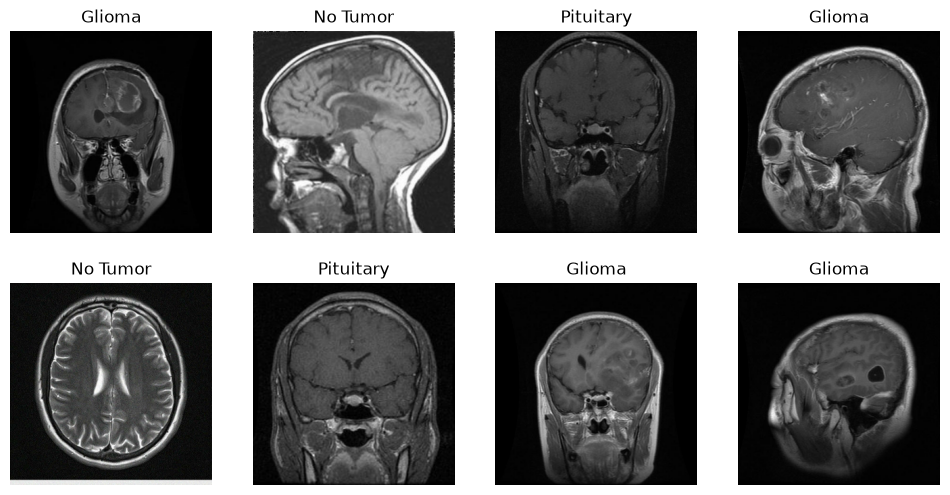

In [19]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 6))
for i in range(8):
    ax = plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(CLASS_NAMES[labels[i]])
    plt.axis("off")
plt.show()

In [20]:
normalization = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1)

x = normalization(images)
print(float(tf.reduce_min(x)), float(tf.reduce_max(x)))

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

-1.0 1.0


In [21]:
import mlflow
import mlflow.keras

PROJECT_ROOT = Path("..").resolve()
mlflow.set_tracking_uri(f"sqlite:///{PROJECT_ROOT / 'mlflow.db'}")

EXPERIMENT = "brain-tumor-classification"
if mlflow.get_experiment_by_name(EXPERIMENT) is None:
    mlflow.create_experiment(EXPERIMENT, artifact_location=(PROJECT_ROOT / "mlruns").as_uri())
mlflow.set_experiment(EXPERIMENT)

2026/10/26 17:47:31 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/26 17:47:31 INFO mlflow.store.db.utils: Updating database tables


<Experiment: artifact_location='file:///home/kerymy/Study-DevAI/DiagnosticMultimodal/mlruns', creation_time=1793036853135, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1793036853135, lifecycle_stage='active', name='brain-tumor-classification', tags={}, trace_location=None, workspace='default'>

In [22]:
inputs  = tf.keras.Input(shape=IMG_SIZE + (3,))
x       = normalization(inputs)
x       = base_model(x, training=False)
x       = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax")(x)

model = tf.keras.Model(inputs, outputs, name="inceptionv3_classifier")
model.summary()

Model: "inceptionv3_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 2048)           │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,810,980 (83.20 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [23]:
FE_PARAMS = {
    "phase": "feature_extraction",
    "backbone": "InceptionV3",
    "img_size": IMG_SIZE[0],
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": 1e-3,
    "loss": "sparse_categorical_crossentropy",
    "dropout": 0.3,
    "max_epochs": 15,
    "early_stopping_patience": 3,
}

model.compile(
    optimizer=tf.keras.optimizers.Adam(FE_PARAMS["learning_rate"]),
    loss=FE_PARAMS["loss"],
    metrics=["accuracy"],
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=FE_PARAMS["early_stopping_patience"],
    restore_best_weights=True,
)

with mlflow.start_run(run_name="inceptionv3-feature-extraction") as run:
    mlflow.log_params(FE_PARAMS)
    fe_history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=FE_PARAMS["max_epochs"],
        callbacks=[early_stopping, mlflow.keras.MlflowCallback()],
    )

FE_RUN_ID = run.info.run_id

/home/kerymy/Study-DevAI/DiagnosticMultimodal/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 50s 205ms/step - accuracy: 0.7361 - loss: 0.6845 - val_accuracy: 0.8221 - val_loss: 0.4936
Epoch 2/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 11s 80ms/step - accuracy: 0.8431 - loss: 0.4213 - val_accuracy: 0.8488 - val_loss: 0.4136
Epoch 3/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 11s 80ms/step - accuracy: 0.8748 - loss: 0.3488 - val_accuracy: 0.8399 - val_loss: 0.4159
Epoch 4/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 11s 82ms/step - accuracy: 0.8860 - loss: 0.3122 - val_accuracy: 0.8628 - val_loss: 0.3529
Epoch 5/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 12s 83ms/step - accuracy: 0.8937 - loss: 0.2893 - val_accuracy: 0.8717 - val_loss: 0.3434
Epoch 6/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 12s 83ms/step - accuracy: 0.8982 - loss: 0.2777 - val_accuracy: 0.8717 - val_loss: 0.3174
Epoch 7/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 11s 78ms/step - accuracy: 0.9087 - loss: 0.2578 - val_accuracy: 0.8780 - val_loss: 0.3142
Epoch 8/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 11s 77ms/step - accuracy: 0.9150 - loss: 0.2405 -

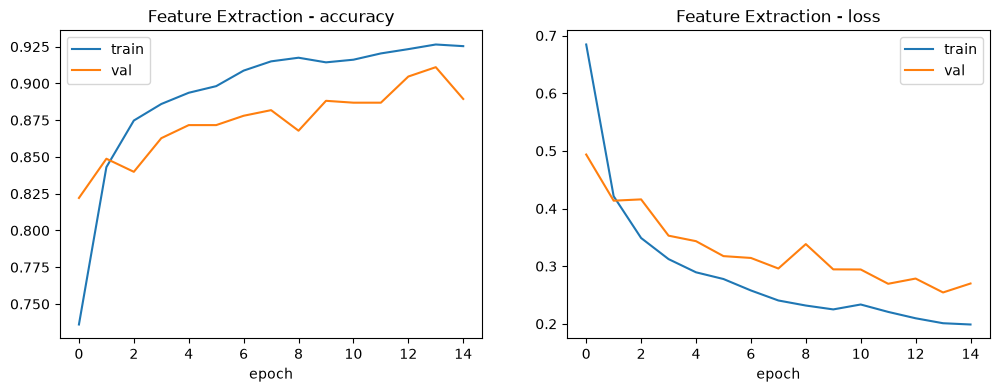

In [24]:
def plot_history(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    for metric, ax in [("accuracy", ax1), ("loss", ax2)]:
        ax.plot(history.history[metric], label="train")
        ax.plot(history.history[f"val_{metric}"], label="val")
        ax.set_title(f"{title} - {metric}")
        ax.set_xlabel("epoch")
        ax.legend()
    plt.show()
    return fig

fig = plot_history(fe_history, "Feature Extraction")

with mlflow.start_run(run_id=FE_RUN_ID):
    mlflow.log_figure(fig, "curves_feature_extraction.png")

In [25]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

LABELS = list(range(len(CLASS_NAMES)))

def get_predictions(model, ds):
    y_true, y_pred = [], []
    for images, labels in ds:
        y_true.append(labels.numpy())
        y_pred.append(model(images, training=False).numpy().argmax(axis=1))
    return np.concatenate(y_true), np.concatenate(y_pred)

def compute_metrics(y_true, y_pred, prefix):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=LABELS, average="macro", zero_division=0
    )
    return {
        f"{prefix}_accuracy": accuracy_score(y_true, y_pred),
        f"{prefix}_precision_macro": precision,
        f"{prefix}_recall_macro": recall,
        f"{prefix}_f1_macro": f1,
    }

def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")
    ax.set_title(title)
    plt.show()
    return fig

In [26]:
test_true, test_pred = get_predictions(model, test_ds)

fe_report = classification_report(test_true, test_pred, labels=LABELS, target_names=CLASS_NAMES, digits=3)
print(fe_report)

              precision    recall  f1-score   support

      Glioma      0.909     0.871     0.889       194
  Meningioma      0.871     0.849     0.860       239
    No Tumor      0.915     0.983     0.948       121
   Pituitary      0.950     0.970     0.960       234

    accuracy                          0.911       788
   macro avg      0.911     0.919     0.914       788
weighted avg      0.911     0.911     0.910       788



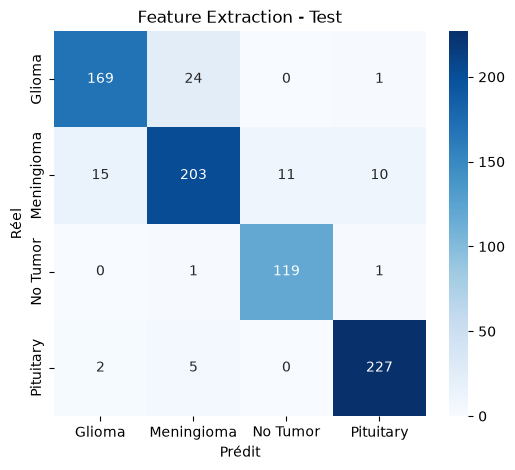

In [27]:
cm_fig = plot_confusion_matrix(test_true, test_pred, "Feature Extraction - Test")

In [28]:
train_true, train_pred = get_predictions(model, train_ds)

fe_metrics = {
    **compute_metrics(train_true, train_pred, "train"),
    **compute_metrics(test_true, test_pred, "test"),
}

comparison = pd.DataFrame({
    split: {k.split("_", 1)[1]: v for k, v in fe_metrics.items() if k.startswith(split)}
    for split in ["train", "test"]
}).round(3)
print(comparison)

with mlflow.start_run(run_id=FE_RUN_ID):
    mlflow.log_metrics(fe_metrics)
    mlflow.log_figure(cm_fig, "confusion_matrix_feature_extraction.png")
    mlflow.log_text(fe_report, "classification_report_feature_extraction.txt")

                 train   test
accuracy         0.956  0.911
precision_macro  0.956  0.911
recall_macro     0.956  0.919
f1_macro         0.956  0.914


In [29]:
val_true, val_pred = get_predictions(model, val_ds)
fe_val_metrics = compute_metrics(val_true, val_pred, "val")
fe_metrics.update(fe_val_metrics)

with mlflow.start_run(run_id=FE_RUN_ID):
    mlflow.log_metrics(fe_val_metrics)

fe_weights = model.get_weights()

def unfreeze_from(block_name):
    base_model.trainable = True
    trainable = False
    for layer in base_model.layers:
        if layer.name == block_name:
            trainable = True
        layer.trainable = trainable and not isinstance(layer, tf.keras.layers.BatchNormalization)
    return sum(int(tf.size(w)) for w in model.trainable_weights)

for block in ["mixed9", "mixed8"]:
    print(block, "→", unfreeze_from(block), "paramètres entraînables")

mixed9 → 6078468 paramètres entraînables
mixed8 → 11116548 paramètres entraînables


In [30]:
FT_PARAMS = {
    "phase": "fine_tuning",
    "backbone": "InceptionV3",
    "img_size": IMG_SIZE[0],
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": 1e-5,
    "loss": "sparse_categorical_crossentropy",
    "dropout": 0.3,
    "max_epochs": 10,
    "early_stopping_patience": 3,
}

def run_fine_tuning(block_name):
    model.set_weights(fe_weights)
    n_trainable = unfreeze_from(block_name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(FT_PARAMS["learning_rate"]),
        loss=FT_PARAMS["loss"],
        metrics=["accuracy"],
    )
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=FT_PARAMS["early_stopping_patience"],
        restore_best_weights=True,
    )

    with mlflow.start_run(run_name=f"inceptionv3-fine-tuning-{block_name}") as run:
        mlflow.log_params({**FT_PARAMS, "unfreeze_from": block_name, "trainable_params": n_trainable})
        history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=FT_PARAMS["max_epochs"],
            callbacks=[early_stopping, mlflow.keras.MlflowCallback()],
        )

        train_true, train_pred = get_predictions(model, train_ds)
        val_true, val_pred = get_predictions(model, val_ds)
        test_true, test_pred = get_predictions(model, test_ds)
        metrics = {
            **compute_metrics(train_true, train_pred, "train"),
            **compute_metrics(val_true, val_pred, "val"),
            **compute_metrics(test_true, test_pred, "test"),
        }
        report = classification_report(test_true, test_pred, labels=LABELS,
                                       target_names=CLASS_NAMES, digits=3, zero_division=0)
        print(report)

        curves_fig = plot_history(history, f"Fine-tuning {block_name}")
        cm_fig = plot_confusion_matrix(test_true, test_pred, f"Fine-tuning {block_name} - Test")

        mlflow.log_metrics(metrics)
        mlflow.log_figure(curves_fig, f"curves_fine_tuning_{block_name}.png")
        mlflow.log_figure(cm_fig, f"confusion_matrix_fine_tuning_{block_name}.png")
        mlflow.log_text(report, f"classification_report_fine_tuning_{block_name}.txt")

    return {"run_id": run.info.run_id, "metrics": metrics, "weights": model.get_weights()}

/home/kerymy/Study-DevAI/DiagnosticMultimodal/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 28s 128ms/step - accuracy: 0.9344 - loss: 0.1821 - val_accuracy: 0.9187 - val_loss: 0.2422
Epoch 2/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 10s 75ms/step - accuracy: 0.9537 - loss: 0.1359 - val_accuracy: 0.9301 - val_loss: 0.2034
Epoch 3/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 10s 75ms/step - accuracy: 0.9690 - loss: 0.0994 - val_accuracy: 0.9339 - val_loss: 0.2030
Epoch 4/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 10s 75ms/step - accuracy: 0.9771 - loss: 0.0726 - val_accuracy: 0.9403 - val_loss: 0.1732
Epoch 5/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 10s 75ms/step - accuracy: 0.9843 - loss: 0.0604 - val_accuracy: 0.9466 - val_loss: 0.1694
Epoch 6/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 10s 75ms/step - accuracy: 0.9879 - loss: 0.0438 - val_accuracy: 0.9441 - val_loss: 0.1671
Epoch 7/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 10s 75ms/step - accuracy: 0.9917 - loss: 0.0337 - val_accuracy: 0.9517 - val_loss: 0.1638
Epoch 8/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 10s 75ms/step - accuracy: 0.9930 - loss: 0.0285 -

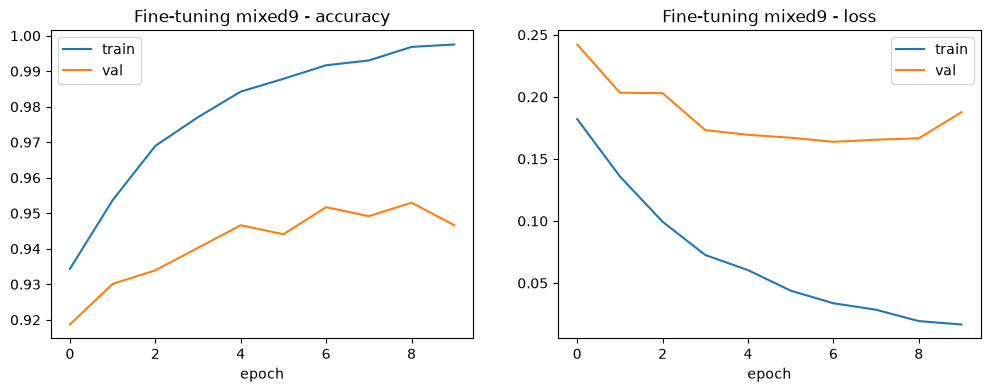

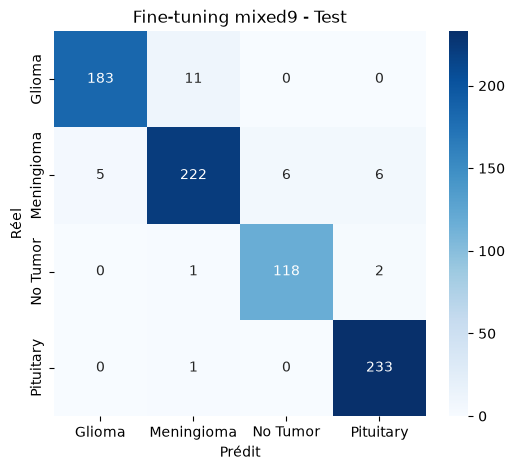

/home/kerymy/Study-DevAI/DiagnosticMultimodal/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 29s 131ms/step - accuracy: 0.9366 - loss: 0.1754 - val_accuracy: 0.9352 - val_loss: 0.1889
Epoch 2/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 11s 82ms/step - accuracy: 0.9667 - loss: 0.0913 - val_accuracy: 0.9504 - val_loss: 0.1550
Epoch 3/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - accuracy: 0.9881 - loss: 0.0436 - val_accuracy: 0.9492 - val_loss: 0.1591
Epoch 4/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - accuracy: 0.9930 - loss: 0.0264 - val_accuracy: 0.9530 - val_loss: 0.1737
Epoch 5/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 11s 82ms/step - accuracy: 0.9966 - loss: 0.0154 - val_accuracy: 0.9581 - val_loss: 0.1452
Epoch 6/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 11s 82ms/step - accuracy: 0.9966 - loss: 0.0126 - val_accuracy: 0.9543 - val_loss: 0.1616
Epoch 7/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 11s 82ms/step - accuracy: 0.9980 - loss: 0.0081 - val_accuracy: 0.9466 - val_loss: 0.1918
Epoch 8/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 11s 82ms/step - accuracy: 0.9991 - loss: 0.0062 -

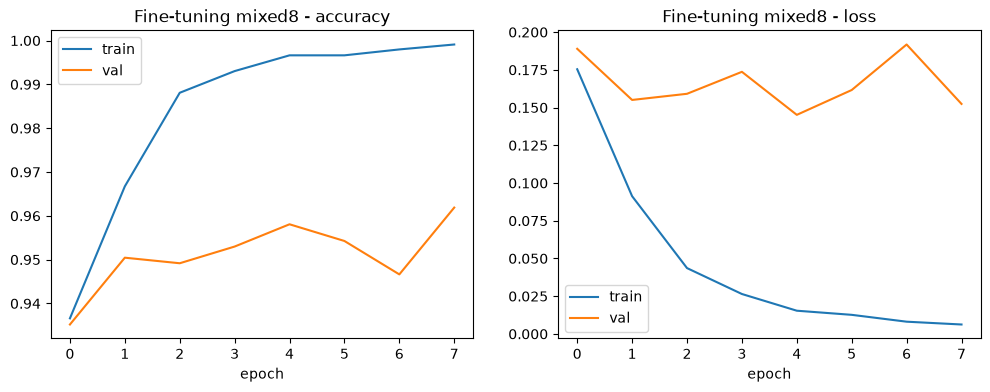

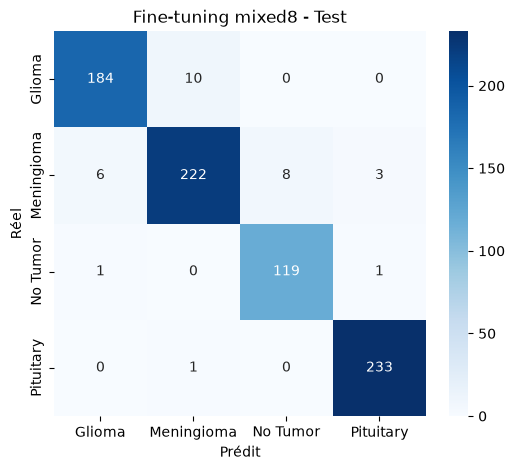

In [31]:
FT_BLOCKS = ["mixed9", "mixed8"]
ft_results = {block: run_fine_tuning(block) for block in FT_BLOCKS}

In [32]:
results = {
    "feature_extraction": {"run_id": FE_RUN_ID, "metrics": fe_metrics, "weights": fe_weights},
    **{f"fine_tuning_{block}": result for block, result in ft_results.items()},
}

ROWS = ["train_accuracy", "val_accuracy", "val_f1_macro",
        "test_accuracy", "test_precision_macro", "test_recall_macro", "test_f1_macro"]
comparison = pd.DataFrame({name: {k: r["metrics"][k] for k in ROWS} for name, r in results.items()}).round(3)
display(comparison)

best_name = max(results, key=lambda name: results[name]["metrics"]["val_f1_macro"])
model.set_weights(results[best_name]["weights"])
BEST_RUN_ID = results[best_name]["run_id"]
print("Modèle retenu :", best_name)

,feature_extraction,fine_tuning_mixed9,fine_tuning_mixed8
train_accuracy,0.956,0.999,1.000
val_accuracy,0.911,0.950,0.958
val_f1_macro,0.913,0.952,0.959
test_accuracy,0.911,0.959,0.962
test_precision_macro,0.911,0.959,0.959
test_recall_macro,0.919,0.961,0.964
test_f1_macro,0.914,0.960,0.961


Modèle retenu : fine_tuning_mixed8


In [33]:
import json
from mlflow.models import infer_signature

MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODELS_DIR / "classifier.keras"
META_PATH = MODELS_DIR / "classifier_meta.json"

model.save(MODEL_PATH)

meta = {
    "class_names": CLASS_NAMES,
    "img_size": list(IMG_SIZE),
    "input": "RGB, pixels bruts 0-255 (normalisation incluse dans le modèle)",
    "config": best_name,
    "mlflow_run_id": BEST_RUN_ID,
    "test_metrics": {k: round(v, 4) for k, v in results[best_name]["metrics"].items() if k.startswith("test_")},
}
META_PATH.write_text(json.dumps(meta, indent=2, ensure_ascii=False))

images, _ = next(iter(test_ds))
signature = infer_signature(images[:1].numpy(), model.predict(images[:1], verbose=0))

with mlflow.start_run(run_id=BEST_RUN_ID):
    mlflow.keras.log_model(model, name="classifier", signature=signature)
    mlflow.log_artifact(str(META_PATH))

print(MODEL_PATH, f"({MODEL_PATH.stat().st_size // 2**20} MB)")

2026/10/26 23:51:22 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


/home/kerymy/Study-DevAI/DiagnosticMultimodal/models/classifier.keras (169 MB)


In [34]:
reloaded = tf.keras.models.load_model(MODEL_PATH)

images, labels = next(iter(test_ds))
same = np.allclose(model.predict(images, verbose=0), reloaded.predict(images, verbose=0), atol=1e-5)
print("Prédictions identiques :", same)

reloaded_true, reloaded_pred = get_predictions(reloaded, test_ds)
print("Test accuracy du modèle rechargé :", round(accuracy_score(reloaded_true, reloaded_pred), 3))

Prédictions identiques : True
Test accuracy du modèle rechargé : 0.962


In [ ]:
CLS_COLUMNS = {
    "params.phase": "phase",
    "params.unfreeze_from": "unfreeze_from",
    "metrics.val_f1_macro": "val_f1",
    "metrics.val_recall_macro": "val_recall",
    "metrics.test_accuracy": "test_accuracy",
    "metrics.test_precision_macro": "test_precision",
    "metrics.test_recall_macro": "test_recall",
    "metrics.test_f1_macro": "test_f1",
}

cls_runs = mlflow.search_runs(experiment_names=[EXPERIMENT], order_by=["metrics.val_f1_macro DESC"])
cls_runs.set_index("tags.mlflow.runName")[list(CLS_COLUMNS)].rename(columns=CLS_COLUMNS).round(3)

In [ ]:
import json
from datetime import date

CLASSIFIER_NAME = "brain-tumor-classifier"
cls_meta = json.loads((PROJECT_ROOT / "models" / "classifier_meta.json").read_text())
cls_test = cls_meta["test_metrics"]

client = mlflow.MlflowClient()
cls_version = mlflow.register_model(f"runs:/{cls_meta['mlflow_run_id']}/classifier", CLASSIFIER_NAME)
client.update_registered_model(CLASSIFIER_NAME, description="Classification d'IRM cérébrales en 4 classes (InceptionV3 fine-tuné)")
client.update_model_version(
    CLASSIFIER_NAME, cls_version.version,
    description=(f"Run {cls_meta['mlflow_run_id']} ({cls_meta['config']}) - "
                 f"test accuracy {cls_test['test_accuracy']}, F1 macro {cls_test['test_f1_macro']}, "
                 f"recall macro {cls_test['test_recall_macro']} - enregistré le {date.today()}"),
)
for key, value in {"task": "classification", "framework": "keras", "config": cls_meta["config"]}.items():
    client.set_model_version_tag(CLASSIFIER_NAME, cls_version.version, key, value)
client.set_registered_model_alias(CLASSIFIER_NAME, "champion", cls_version.version)

In [ ]:
champion = mlflow.pyfunc.load_model(f"models:/{CLASSIFIER_NAME}@champion")
print("Run source :", champion.metadata.run_id)

for class_name in cls_meta["class_names"]:
    image_path = next((PROJECT_ROOT / "processed" / "classification" / "test" / class_name).glob("*.jpg"))
    x = np.expand_dims(np.array(Image.open(image_path).convert("RGB").resize(tuple(cls_meta["img_size"])), dtype="float32"), 0)
    print(class_name, "→", cls_meta["class_names"][int(np.asarray(champion.predict(x)).argmax())])